# TP1 · Ejercicio 2 — NER con DistilBERT sobre CoNLL-2003: LoRA vs. full fine-tuning

**Inteligencia Artificial y Aprendizaje Profundo II — UCA** · Prof. José Canelón, Ph.D.

**Integrantes:** Matías Adell · Agustín Giannice · Facundo Mazzola

**Consignas**
1. Cargar `eriktks/conll2003` y tokenizar (tarea: NER).
2. Fine-tuning de `distilbert-base-cased` con **LoRA** (`get_peft_model`, módulos de atención) y, bajo las mismas condiciones, **full fine-tuning**.
3. Comparar full vs. LoRA: F1/accuracy, parámetros entrenables (`print_trainable_parameters`), memoria de GPU y tamaño del checkpoint (full en GB vs. adaptador en MB).

**Índice**
1. Configuración y reproducibilidad
2. Datos: CoNLL-2003
3. Tokenización y alineación de etiquetas
4. Métricas y utilidades de medición
5. Tres formas de adaptar el modelo: linear probe, full y LoRA
6. Entrenamiento y curvas
7. Comparación: antes vs. después, full vs. LoRA
8. Reporte por entidad e inferencia
9. Conclusiones (calculadas desde las métricas)
10. Referencias

> Requiere GPU (Colab T4). Con `SMOKE_TEST=True` (o la variable de entorno `TP1_SMOKE_TEST=1`) corre en CPU con un subconjunto diminuto y 1 época, solo para verificar que el notebook funciona de punta a punta.

## 1. Configuración y reproducibilidad

Instalamos el stack de la cátedra (como en NB2) y desinstalamos `torchao`, cuya versión en Colab rompe a `peft`. Los checkpoints van a Google Drive para poder **reanudar** si la sesión se corta; fuera de Colab se usa una carpeta local. Fijamos la semilla, detectamos el dispositivo e imprimimos versiones e hiperparámetros.

In [1]:
import os, sys, random, json, time, math, shutil, gc

# 1) Colab: instalación y Drive (solo si corresponde)
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    %pip install -q -U transformers datasets accelerate peft evaluate seqeval
    %pip uninstall -q -y torchao

# 2) Modo smoke test (subset diminuto + 1 época) activable por variable de entorno
SMOKE_TEST = os.environ.get('TP1_SMOKE_TEST') == '1'

# 3) Carpeta de trabajo: Drive en Colab, carpeta local si no
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/Colab_Notebooks/TP1_Adell_Giannice_Mazzola/ej2'
else:
    BASE = os.environ.get('TP1_LOCAL_DIR', './tp1_local') + '/ej2'
os.makedirs(BASE, exist_ok=True)

# 4) Semilla y dispositivo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers, datasets, peft, evaluate, accelerate
from transformers import set_seed

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); set_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_FP16 = torch.cuda.is_available()  # fp16 solo con GPU

# 5) Versiones e hiperparámetros
print('IN_COLAB:', IN_COLAB, '| SMOKE_TEST:', SMOKE_TEST, '| device:', device,
      f'({torch.cuda.get_device_name(0)})' if device == 'cuda' else '')
print('BASE =', BASE)
for lib in (torch, transformers, datasets, peft, evaluate, accelerate, np, pd):
    print(f'{lib.__name__:>13s} {lib.__version__}')

HPARAMS = {
    'modelo': 'distilbert-base-cased',
    'dataset': 'eriktks/conll2003 (refs/convert/parquet)',
    'max_length': 128,
    'batch_size': 16,
    'eval_batch_size': 32,
    'epochs': 1 if SMOKE_TEST else 3,          # full y LoRA
    'epochs_probe': 1,                          # "antes" = linear probe de 1 época
    'lr_full': 2e-5,
    'lr_lora': 1e-3,
    'lr_probe': 1e-3,
    'weight_decay': 0.01,
    'warmup_ratio': 0.1,
    'lr_scheduler': 'cosine',
    'early_stopping_patience': 1,
    'lora_r': 8,
    'lora_alpha': 16,
    'lora_dropout': 0.05,
    'lora_target_modules': ['q_lin', 'v_lin'],
    'fp16': USE_FP16,
    'seed': SEED,
    'smoke_subset (train/val/test)': (64, 32, 32) if SMOKE_TEST else None,
}
pd.Series(HPARAMS, name='valor').to_frame()

IN_COLAB: False | SMOKE_TEST: True | device: cpu 
BASE = C:/Users/facum/tp1_cache/ej2
        torch 2.14.0+cpu
 transformers 5.17.0
     datasets 5.0.1
         peft 0.21.0
     evaluate 0.4.6
   accelerate 1.15.0
        numpy 2.4.6
       pandas 3.0.6


,valor
modelo,distilbert-base-cased
dataset,eriktks/conll2003 (refs/convert/parquet)
max_length,128
batch_size,16
eval_batch_size,32
epochs,1
epochs_probe,1
lr_full,0.00002
lr_lora,0.001
lr_probe,0.001


## 2. Datos: CoNLL-2003

**CoNLL-2003** (Tjong Kim Sang & De Meulder, 2003) es el benchmark clásico de *Named Entity Recognition* en inglés (noticias de Reuters). Cada ejemplo es una oración ya separada en palabras (`tokens`) con una etiqueta por palabra (`ner_tags`) en esquema **IOB2**: `B-X` abre una entidad de tipo X, `I-X` la continúa y `O` marca palabras fuera de toda entidad. Hay cuatro tipos: **PER** (personas), **ORG** (organizaciones), **LOC** (lugares) y **MISC** (misceláneas: nacionalidades, eventos, etc.).

El repo `eriktks/conll2003` solo trae un script de carga (`conll2003.py`) que `datasets` ≥ 4 ya no ejecuta, así que cargamos la conversión oficial a parquet (`revision="refs/convert/parquet"`). El dataset es chico, por lo que se usa **completo** con sus splits oficiales train / validation / test.

In [2]:
from datasets import load_dataset

raw = load_dataset('eriktks/conll2003', revision='refs/convert/parquet')

label_names = list(raw['train'].features['ner_tags'].feature.names)   # ClassLabel del dataset
id2label = dict(enumerate(label_names))
label2id = {l: i for i, l in id2label.items()}
print('Etiquetas:', label_names)

if SMOKE_TEST:
    n_tr, n_va, n_te = HPARAMS['smoke_subset (train/val/test)']
    raw['train'] = raw['train'].shuffle(seed=SEED).select(range(n_tr))
    raw['validation'] = raw['validation'].shuffle(seed=SEED).select(range(n_va))
    raw['test'] = raw['test'].shuffle(seed=SEED).select(range(n_te))
print(raw)

Etiquetas: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 64
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 32
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 32
    })
})


In [3]:
# Algunos ejemplos: palabra -> etiqueta
for ex in raw['train'].select(range(3)):
    print(' '.join(f'{w}/{id2label[t]}' for w, t in zip(ex['tokens'], ex['ner_tags'])))
    print()

"/O Neither/O the/O National/B-MISC Socialists/I-MISC (/O Nazis/B-MISC )/O nor/O the/O communists/O dared/O to/O kidnap/O an/O American/B-MISC citizen/O ,/O "/O he/O shouted/O ,/O in/O an/O oblique/O reference/O to/O his/O extradition/O to/O Germany/B-LOC from/O Denmark/B-LOC ./O "/O

TUNIS/B-LOC 1996-08-22/O

Werder/B-ORG Bremen/I-ORG 3/O 0/O 1/O 2/O 4/O 6/O 1/O



,oraciones,palabras,ORG,LOC,MISC,PER
split,,,,,,
train,64,926,33,28,20,19
validation,32,430,12,26,6,18
test,32,466,17,16,8,32


     train: 83.7% de las palabras tienen etiqueta O
validation: 80.5% de las palabras tienen etiqueta O
      test: 75.8% de las palabras tienen etiqueta O


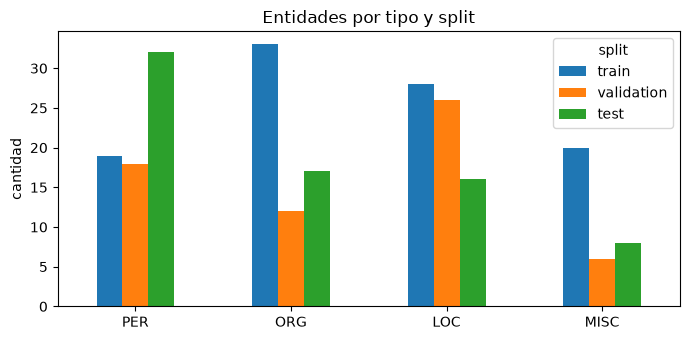

In [4]:
# Distribución de entidades (se cuentan los B-*, una por entidad) y de etiquetas por palabra
def contar(split):
    tags = [id2label[t] for seq in list(raw[split]['ner_tags']) for t in seq]
    ent = pd.Series([t[2:] for t in tags if t.startswith('B-')]).value_counts()
    return len(raw[split]), len(tags), ent, pd.Series(tags).value_counts(normalize=True)

filas, prop_O = [], {}
for split in ['train', 'validation', 'test']:
    n_or, n_pal, ent, prop = contar(split)
    filas.append({'split': split, 'oraciones': n_or, 'palabras': n_pal, **ent.to_dict()})
    prop_O[split] = prop.get('O', 0.0)
dist = pd.DataFrame(filas).set_index('split').fillna(0).astype(int)
display(dist)
for split, p in prop_O.items():
    print(f'{split:>10s}: {100 * p:.1f}% de las palabras tienen etiqueta O')

ents = [c for c in ['PER', 'ORG', 'LOC', 'MISC'] if c in dist.columns]
dist[ents].T.plot.bar(figsize=(7, 3.5), rot=0, title='Entidades por tipo y split')
plt.ylabel('cantidad'); plt.tight_layout(); plt.show()

La etiqueta `O` domina ampliamente: una **accuracy por token** alta se consigue casi prediciendo siempre `O`. Por eso la métrica principal es el **F1 a nivel entidad** (seqeval), que solo cuenta una entidad como correcta si coinciden su tipo y sus límites exactos.

## 3. Tokenización y alineación de etiquetas

DistilBERT usa **WordPiece**: una palabra puede partirse en varios subtokens (`Leicestershire` → `Leicester`, `##shire`), y además se agregan `[CLS]` y `[SEP]`. Como las etiquetas están **por palabra**, hay que alinearlas a los subtokens:

- Tokenizamos con `is_split_into_words=True` (el texto ya viene separado en palabras) y usamos `word_ids()` para saber a qué palabra pertenece cada subtoken.
- Solo el **primer subtoken** de cada palabra lleva la etiqueta; los subtokens siguientes y los tokens especiales reciben `-100`, que la *cross-entropy* de PyTorch ignora. Así cada palabra aporta exactamente una predicción a la pérdida y a la métrica.
- Se usa el modelo **cased**: en NER la mayúscula inicial es una señal fuerte de nombre propio.
- `DataCollatorForTokenClassification` hace el *padding* dinámico por batch, rellenando también las etiquetas con `-100`.

In [5]:
from transformers import AutoTokenizer, DataCollatorForTokenClassification

MODEL = HPARAMS['modelo']
MAX_LEN = HPARAMS['max_length']
tokenizer = AutoTokenizer.from_pretrained(MODEL)

# Largo en subtokens (sin truncar) para justificar max_length
largos = [len(ids) for ids in tokenizer(list(raw['train']['tokens']), is_split_into_words=True)['input_ids']]
print(f'Subtokens por oración (train): media={np.mean(largos):.1f}, p99={np.percentile(largos, 99):.0f}, '
      f'máx={max(largos)}; {100 * np.mean(np.array(largos) > MAX_LEN):.3f}% supera max_length={MAX_LEN}')

Subtokens por oración (train): media=21.4, p99=54, máx=67; 0.000% supera max_length=128


In [6]:
def tokenize_and_align(batch):
    enc = tokenizer(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LEN)
    all_labels = []
    for i, tags in enumerate(batch['ner_tags']):
        prev, labels = None, []
        for wid in enc.word_ids(batch_index=i):
            if wid is None or wid == prev:
                labels.append(-100)          # especial o subtoken no inicial
            else:
                labels.append(tags[wid])     # primer subtoken de la palabra
            prev = wid
        all_labels.append(labels)
    enc['labels'] = all_labels
    return enc

ds_tok = raw.map(tokenize_and_align, batched=True, remove_columns=raw['train'].column_names)
print(ds_tok)

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 64
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 32
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 32
    })
})


In [7]:
# Ejemplo visual: subtoken <-> palabra <-> etiqueta alineada
ej = raw['train'][0]
enc = tokenizer(ej['tokens'], is_split_into_words=True)
pd.DataFrame({
    'subtoken': tokenizer.convert_ids_to_tokens(enc['input_ids']),
    'word_id': enc.word_ids(),
    'label_id': ds_tok['train'][0]['labels'],
    'label': [id2label[l] if l != -100 else '-100 (ignorado)' for l in ds_tok['train'][0]['labels']],
}).T

,0,1,2,3,4,5,6,7,8,9,...,29,30,31,32,33,34,35,36,37,38
subtoken,[CLS],"""",Neither,the,National,Socialist,##s,(,Nazis,),...,his,extra,##dition,to,Germany,from,Denmark,.,"""",[SEP]
word_id,NaN,0.0,1.0,2.0,3.0,4.0,4.0,5.0,6.0,7.0,...,27.0,28.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,NaN
label_id,-100,0,0,0,7,8,-100,0,7,0,...,0,0,-100,0,5,0,5,0,0,-100
label,-100 (ignorado),O,O,O,B-MISC,I-MISC,-100 (ignorado),O,B-MISC,O,...,O,O,-100 (ignorado),O,B-LOC,O,B-LOC,O,O,-100 (ignorado)


In [8]:
collator = DataCollatorForTokenClassification(tokenizer)
batch = collator([ds_tok['train'][i] for i in range(2)])
print({k: tuple(v.shape) for k, v in batch.items()})
print('labels (padding con -100):', batch['labels'][1].tolist())

{'input_ids': (2, 39), 'token_type_ids': (2, 39), 'attention_mask': (2, 39), 'labels': (2, 39)}
labels (padding con -100): [-100, 5, -100, -100, 0, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100]


## 4. Métricas y utilidades de medición

- **seqeval** (vía `evaluate`) reconstruye las entidades a partir de las secuencias IOB2 y calcula **precision, recall y F1 a nivel entidad** (micro sobre todas las entidades) más la **accuracy por palabra**. Se descartan las posiciones con `-100`, así se evalúa exactamente una etiqueta por palabra.
- `n_trainable` / `n_total`: conteo de parámetros (el equivalente a `print_trainable_parameters` para full y probe).
- `dir_size_mb`: tamaño en disco de un checkpoint (suma de archivos, como en NB2).
- Memoria: `torch.cuda.reset_peak_memory_stats()` antes de entrenar y `torch.cuda.max_memory_allocated()` después (pico de memoria asignada por tensores). Sin CUDA se reporta N/A.

In [9]:
import evaluate

seqeval = evaluate.load('seqeval')

def to_label_seqs(logits, label_ids):
    preds = np.argmax(logits, axis=-1)
    y_true, y_pred = [], []
    for p_row, l_row in zip(preds, label_ids):
        mask = l_row != -100
        y_true.append([id2label[int(l)] for l in l_row[mask]])
        y_pred.append([id2label[int(p)] for p in p_row[mask]])
    return y_true, y_pred

def compute_metrics(p):
    y_true, y_pred = to_label_seqs(p.predictions, p.label_ids)
    r = seqeval.compute(predictions=y_pred, references=y_true, zero_division=0)
    return {'precision': r['overall_precision'], 'recall': r['overall_recall'],
            'f1': r['overall_f1'], 'accuracy': r['overall_accuracy']}

def n_trainable(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
def n_total(m): return sum(p.numel() for p in m.parameters())

def dir_size_mb(path):
    tot = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(path) for f in fs)
    return tot / 1e6

def fmt_size(mb, mode):
    # Full/probe = modelo completo (GB); LoRA = solo adaptador (MB)
    return f'{mb:.2f} MB' if mode == 'lora' else f'{mb / 1e3:.3f} GB'

## 5. Tres formas de adaptar el modelo: linear probe, full y LoRA

DistilBERT es un **encoder-only** (Sanh et al., 2019): 6 capas Transformer destiladas de BERT, con atención bidireccional. Para NER, `AutoModelForTokenClassification` agrega una **cabeza lineal sobre cada token** (`classifier`, 768 → 9 etiquetas) que se inicializa al azar.

| modo | qué se entrena | rol en la comparación |
|---|---|---|
| `probe` | solo `classifier` (se congela todo `distilbert.*`), 1 época | **"antes" del fine-tuning**: mide qué tan buenas son las features preentrenadas tal cual |
| `full` | todos los pesos | fine-tuning completo |
| `lora` | matrices LoRA en `q_lin` y `v_lin` + `classifier` (`modules_to_save`) | fine-tuning eficiente en parámetros |

**LoRA** (Hu et al., 2021) congela cada peso $W_0 \in \mathbb{R}^{d\times k}$ y aprende una actualización de rango bajo:
$$W = W_0 + \frac{\alpha}{r}\,BA,\qquad B\in\mathbb{R}^{d\times r},\; A\in\mathbb{R}^{r\times k},\; r \ll \min(d,k)$$
con $B=0$ al inicio (el modelo arranca idéntico al preentrenado). Por matriz adaptada se entrenan $r(d+k)$ parámetros. Se inyecta en las proyecciones de atención *query* y *value* (`q_lin`, `v_lin`), como en el paper original y en NB2. La cabeza es nueva, así que también debe entrenarse: `modules_to_save=['classifier']` la deja entrenable y la guarda junto al adaptador.

**Mismas condiciones.** Los tres modos comparten datos, tokenización (`max_length`), batch, scheduler (warmup + coseno), weight decay, semilla, precisión (fp16 en GPU), evaluación y guardado por época y selección del mejor checkpoint por F1 de validación (`load_best_model_at_end`, con early stopping de paciencia 1). Solo cambian el **learning rate** (LoRA y el probe entrenan pocos parámetros nuevos y toleran/necesitan un LR mayor, como en la cátedra) y, en el probe, la cantidad de épocas.

**Reanudación y caché.** Cada modo guarda checkpoints por época en `BASE/out_<modo>`; si la sesión se corta, al volver a correr se reanuda desde el último (`resume_from_checkpoint`). Al terminar se guarda el modelo final (`ckpt_<modo>`: full con `save_model`, LoRA con `save_pretrained`, que escribe **solo el adaptador**) y un JSON con las métricas, así que una corrida completa no se repite (salvo `REENTRENAR = True`). En smoke test siempre se entrena desde cero.

In [10]:
from transformers import (AutoConfig, AutoModelForTokenClassification, TrainingArguments, Trainer,
                          EarlyStoppingCallback)
from transformers.trainer_utils import get_last_checkpoint
from peft import LoraConfig, get_peft_model, TaskType, PeftModel

REENTRENAR = False
USAR_CACHE = not SMOKE_TEST and not REENTRENAR

def load_base_model():
    return AutoModelForTokenClassification.from_pretrained(
        MODEL, num_labels=len(label_names), id2label=id2label, label2id=label2id)

def build_model(mode):
    model = load_base_model()
    if mode == 'probe':
        for name, p in model.named_parameters():
            p.requires_grad = not name.startswith('distilbert.')
    elif mode == 'lora':
        lora_cfg = LoraConfig(task_type=TaskType.TOKEN_CLS, r=HPARAMS['lora_r'],
                              lora_alpha=HPARAMS['lora_alpha'], lora_dropout=HPARAMS['lora_dropout'],
                              target_modules=HPARAMS['lora_target_modules'],
                              modules_to_save=['classifier'])
        model = get_peft_model(model, lora_cfg)
        model.print_trainable_parameters()
    tr, tot = n_trainable(model), n_total(model)
    print(f'[{mode}] parámetros entrenables: {tr:,} de {tot:,} ({100 * tr / tot:.4f}%)')
    return model

def make_args(mode, lr, epochs):
    # Idénticos para los tres modos salvo learning rate y épocas
    steps_per_epoch = math.ceil(len(ds_tok['train']) / HPARAMS['batch_size'])
    return TrainingArguments(
        output_dir=f'{BASE}/out_{mode}',
        per_device_train_batch_size=HPARAMS['batch_size'],
        per_device_eval_batch_size=HPARAMS['eval_batch_size'],
        num_train_epochs=epochs,
        learning_rate=lr,
        weight_decay=HPARAMS['weight_decay'],
        warmup_steps=HPARAMS['warmup_ratio'],       # float < 1 = proporción de los pasos totales
        lr_scheduler_type=HPARAMS['lr_scheduler'],
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='steps',
        logging_steps=max(1, steps_per_epoch // 10),
        load_best_model_at_end=True,
        metric_for_best_model='f1',
        greater_is_better=True,
        save_total_limit=2,
        label_names=['labels'],
        fp16=USE_FP16,
        seed=SEED,
        report_to='none',
    )

In [11]:
def run_experiment(mode, lr, epochs):
    out_dir, ckpt_dir = f'{BASE}/out_{mode}', f'{BASE}/ckpt_{mode}'
    res_path = f'{BASE}/resultados_{mode}.json'
    set_seed(SEED)
    model = build_model(mode)

    if USAR_CACHE and os.path.exists(res_path) and os.path.isdir(ckpt_dir):
        print(f'[{mode}] resultados encontrados en {res_path}: se reutilizan (REENTRENAR=True para repetir).')
        with open(res_path) as f:
            return json.load(f)
    if SMOKE_TEST:
        shutil.rmtree(out_dir, ignore_errors=True)

    trainer = Trainer(model=model, args=make_args(mode, lr, epochs),
                      train_dataset=ds_tok['train'], eval_dataset=ds_tok['validation'],
                      data_collator=collator, processing_class=tokenizer,
                      compute_metrics=compute_metrics,
                      callbacks=[EarlyStoppingCallback(HPARAMS['early_stopping_patience'])])

    last = get_last_checkpoint(out_dir) if os.path.isdir(out_dir) else None
    if last:
        print(f'[{mode}] reanudando desde {last}')
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    trainer.train(resume_from_checkpoint=last)
    train_time = time.time() - t0
    peak_gb = torch.cuda.max_memory_allocated() / 1e9 if torch.cuda.is_available() else None

    # Evaluación en test con el mejor checkpoint (load_best_model_at_end)
    pred = trainer.predict(ds_tok['test'])
    y_true, y_pred = to_label_seqs(pred.predictions, pred.label_ids)
    rep = seqeval.compute(predictions=y_pred, references=y_true, zero_division=0)
    per_entity = {k: v for k, v in rep.items() if isinstance(v, dict)}

    # Guardado: full/probe = modelo completo; LoRA = solo el adaptador (+ classifier)
    shutil.rmtree(ckpt_dir, ignore_errors=True)
    if mode == 'lora':
        trainer.model.save_pretrained(ckpt_dir)
    else:
        trainer.save_model(ckpt_dir)
    size_mb = dir_size_mb(ckpt_dir)

    res = {
        'mode': mode, 'lr': lr, 'epochs': epochs,
        'test': {k.replace('test_', ''): v for k, v in pred.metrics.items()},
        'per_entity': per_entity,
        'y_true': y_true, 'y_pred': y_pred,
        'n_trainable': n_trainable(trainer.model), 'n_total': n_total(trainer.model),
        'peak_mem_gb': peak_gb, 'train_time_s': train_time,
        'ckpt_dir': ckpt_dir, 'ckpt_mb': size_mb,
        'best_checkpoint': trainer.state.best_model_checkpoint,
        'log_history': trainer.state.log_history,
    }
    with open(res_path, 'w') as f:
        json.dump(res, f, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
    print(f"[{mode}] test F1={res['test']['f1']:.4f} acc={res['test']['accuracy']:.4f} | "
          f"tiempo={train_time / 60:.1f} min | checkpoint={fmt_size(size_mb, mode)}")

    del trainer, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return res

## 6. Entrenamiento y curvas

### 6.1 Antes del fine-tuning: linear probe (1 época)

Con el backbone congelado, solo la cabeza lineal aprende a leer las representaciones preentrenadas. Es la referencia "antes": una cabeza aleatoria sin entrenar daría un resultado trivial (azar sobre 9 clases), que no dice nada sobre el modelo; el probe mide la calidad intrínseca de las features y deja los deltas full−probe y LoRA−probe como la ganancia real de adaptar el backbone.

In [12]:
resultados = {}
resultados['probe'] = run_experiment('probe', HPARAMS['lr_probe'], HPARAMS['epochs_probe'])

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


E:\Programs\miniconda\envs\tp1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[probe] parámetros entrenables: 6,921 de 65,197,833 (0.0106%)


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,2.005708,1.965673,0.053254,0.145161,0.077922,0.402326


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

E:\Programs\miniconda\envs\tp1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[probe] test F1=0.1502 acc=0.3498 | tiempo=0.0 min | checkpoint=0.261 GB


### 6.2 Full fine-tuning (se actualizan todos los pesos)

In [13]:
resultados['full'] = run_experiment('full', HPARAMS['lr_full'], HPARAMS['epochs'])

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[full] parámetros entrenables: 65,197,833 de 65,197,833 (100.0000%)


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,2.023641,1.989570,0.026144,0.064516,0.037209,0.351163


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

E:\Programs\miniconda\envs\tp1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[full] test F1=0.0640 acc=0.3176 | tiempo=0.1 min | checkpoint=0.261 GB


### 6.3 LoRA (backbone congelado + adaptadores de rango bajo en `q_lin`/`v_lin`)

In [14]:
resultados['lora'] = run_experiment('lora', HPARAMS['lr_lora'], HPARAMS['epochs'])

# Chequeo: parámetros LoRA esperados = capas x matrices x r(d+k) + cabeza
cfg = AutoConfig.from_pretrained(MODEL)
esperado = (cfg.n_layers * len(HPARAMS['lora_target_modules']) * HPARAMS['lora_r'] * (cfg.dim + cfg.dim)
            + cfg.dim * len(label_names) + len(label_names))
print(f"LoRA: esperado {esperado:,} entrenables (r·(d+k) por matriz + classifier) | medido {resultados['lora']['n_trainable']:,}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 154,377 || all params: 65,352,210 || trainable%: 0.2362
[lora] parámetros entrenables: 154,377 de 65,352,210 (0.2362%)


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,1.939129,1.887873,0.050847,0.096774,0.066667,0.579070


E:\Programs\miniconda\envs\tp1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[lora] test F1=0.1321 acc=0.4742 | tiempo=0.1 min | checkpoint=0.63 MB


LoRA: esperado 154,377 entrenables (r·(d+k) por matriz + classifier) | medido 154,377


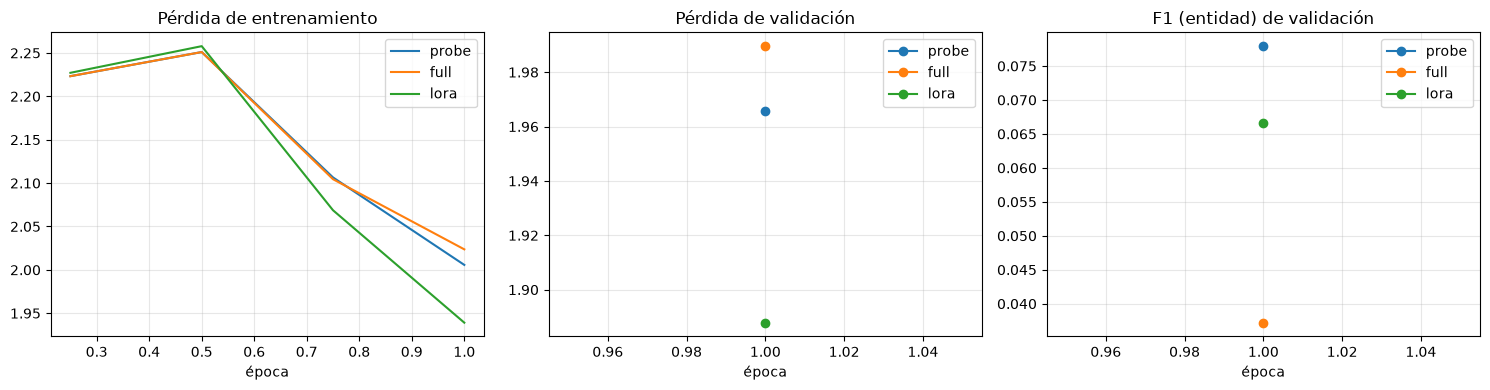

probe: mejor F1 de validación 0.0779 en la época 1 (de 1 evaluadas) -> checkpoint usado en test: C:/Users/facum/tp1_cache/ej2/out_probe\checkpoint-4
 full: mejor F1 de validación 0.0372 en la época 1 (de 1 evaluadas) -> checkpoint usado en test: C:/Users/facum/tp1_cache/ej2/out_full\checkpoint-4
 lora: mejor F1 de validación 0.0667 en la época 1 (de 1 evaluadas) -> checkpoint usado en test: C:/Users/facum/tp1_cache/ej2/out_lora\checkpoint-4


In [15]:
# Curvas: pérdida de train (por pasos de logging) y pérdida/F1 de validación por época
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for mode, res in resultados.items():
    hist = res['log_history']
    tr = [(h['epoch'], h['loss']) for h in hist if 'loss' in h]
    ev = [(h['epoch'], h['eval_loss'], h['eval_f1']) for h in hist if 'eval_f1' in h]
    if tr:
        axes[0].plot(*zip(*tr), label=mode)
    if ev:
        e, l, f = zip(*ev)
        axes[1].plot(e, l, 'o-', label=mode)
        axes[2].plot(e, f, 'o-', label=mode)
for ax, t in zip(axes, ['Pérdida de entrenamiento', 'Pérdida de validación', 'F1 (entidad) de validación']):
    ax.set_title(t); ax.set_xlabel('época'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

for mode, res in resultados.items():
    evs = [h for h in res['log_history'] if 'eval_f1' in h]
    if evs:
        best = max(evs, key=lambda h: h['eval_f1'])
        print(f"{mode:>5s}: mejor F1 de validación {best['eval_f1']:.4f} en la época {best['epoch']:.0f} "
              f"(de {len(evs)} evaluadas) -> checkpoint usado en test: {res['best_checkpoint']}")

## 7. Comparación: antes vs. después, full vs. LoRA

Todas las métricas son sobre el split **test** oficial, con el mejor checkpoint de validación de cada modo. Los deltas se calculan contra el linear probe. El tamaño del checkpoint es lo que se escribe a disco al final: para full y probe el modelo completo (se expresa en GB), para LoRA solo el adaptador y la cabeza (en MB). La memoria es el pico de memoria de GPU asignada durante el entrenamiento.

In [16]:
NOMBRES = {'probe': 'Linear probe (antes)', 'full': 'Full fine-tuning', 'lora': 'LoRA'}
filas = []
for mode, r in resultados.items():
    t = r['test']
    filas.append({
        'método': NOMBRES[mode],
        'F1 test': t['f1'], 'accuracy test': t['accuracy'],
        'precision': t['precision'], 'recall': t['recall'],
        'ΔF1 vs probe': t['f1'] - resultados['probe']['test']['f1'],
        'Δacc vs probe': t['accuracy'] - resultados['probe']['test']['accuracy'],
        'params entrenables': r['n_trainable'],
        '% entrenable': 100 * r['n_trainable'] / r['n_total'],
        'memoria pico GPU (GB)': 'N/A' if r['peak_mem_gb'] is None else round(r['peak_mem_gb'], 2),
        'checkpoint': fmt_size(r['ckpt_mb'], mode),
        'checkpoint (MB)': r['ckpt_mb'],
        'épocas': r['epochs'], 'LR': r['lr'],
        'tiempo (min)': r['train_time_s'] / 60,
    })
tabla = pd.DataFrame(filas).set_index('método')
tabla.style.format({'F1 test': '{:.4f}', 'accuracy test': '{:.4f}', 'precision': '{:.4f}', 'recall': '{:.4f}',
                    'ΔF1 vs probe': '{:+.4f}', 'Δacc vs probe': '{:+.4f}', 'params entrenables': '{:,}',
                    '% entrenable': '{:.3f}', 'checkpoint (MB)': '{:.2f}', 'LR': '{:.0e}',
                    'tiempo (min)': '{:.2f}'})

,F1 test,accuracy test,precision,recall,ΔF1 vs probe,Δacc vs probe,params entrenables,% entrenable,memoria pico GPU (GB),checkpoint,checkpoint (MB),épocas,LR,tiempo (min)
método,,,,,,,,,,,,,,
Linear probe (antes),0.1502,0.3498,0.1056,0.2603,+0.0000,+0.0000,"6,921",0.011,N/A,0.261 GB,261.48,1,1e-03,0.03
Full fine-tuning,0.0640,0.3176,0.0452,0.1096,-0.0862,-0.0322,"65,197,833",100.000,N/A,0.261 GB,261.48,1,2e-05,0.09
LoRA,0.1321,0.4742,0.1007,0.1918,-0.0181,+0.1245,"154,377",0.236,N/A,0.63 MB,0.63,1,1e-03,0.07


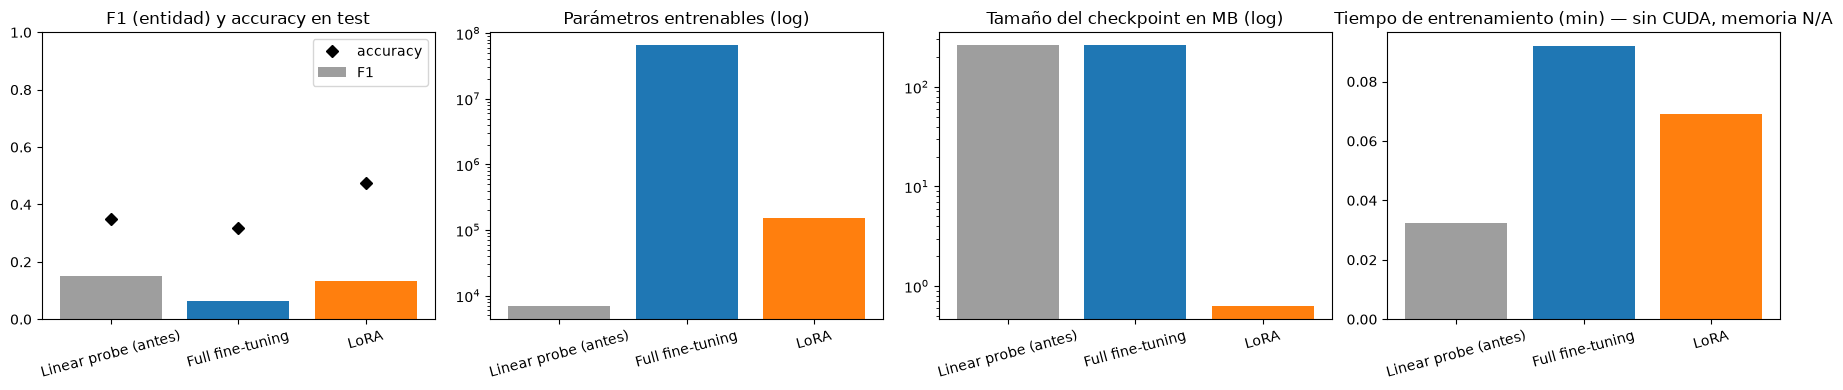

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
colores = ['#9e9e9e', '#1f77b4', '#ff7f0e']
etiquetas = [NOMBRES[m] for m in resultados]

axes[0].bar(etiquetas, [r['test']['f1'] for r in resultados.values()], color=colores, label='F1')
axes[0].plot(etiquetas, [r['test']['accuracy'] for r in resultados.values()], 'kD', label='accuracy')
axes[0].set_title('F1 (entidad) y accuracy en test'); axes[0].set_ylim(0, 1); axes[0].legend()

axes[1].bar(etiquetas, [r['n_trainable'] for r in resultados.values()], color=colores)
axes[1].set_yscale('log'); axes[1].set_title('Parámetros entrenables (log)')

axes[2].bar(etiquetas, [r['ckpt_mb'] for r in resultados.values()], color=colores)
axes[2].set_yscale('log'); axes[2].set_title('Tamaño del checkpoint en MB (log)')

mem = [r['peak_mem_gb'] for r in resultados.values()]
if all(m is not None for m in mem):
    axes[3].bar(etiquetas, mem, color=colores); axes[3].set_title('Memoria pico de GPU (GB)')
else:
    axes[3].bar(etiquetas, [r['train_time_s'] / 60 for r in resultados.values()], color=colores)
    axes[3].set_title('Tiempo de entrenamiento (min) — sin CUDA, memoria N/A')
for ax in axes:
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

## 8. Reporte por entidad e inferencia

`classification_report` de seqeval desglosa precision/recall/F1 por tipo de entidad; permite ver si LoRA pierde calidad de manera uniforme o en algún tipo en particular (típicamente MISC, la clase más heterogénea).

In [18]:
from seqeval.metrics import classification_report

for mode in ['full', 'lora']:
    print(f'=== {NOMBRES[mode]} ===')
    print(classification_report(resultados[mode]['y_true'], resultados[mode]['y_pred'], digits=4, zero_division=0))

por_entidad = pd.DataFrame({
    (NOMBRES[m], met): {e: v[met] for e, v in resultados[m]['per_entity'].items()}
    for m in resultados for met in ['precision', 'recall', 'f1']
})
por_entidad.round(4)

=== Full fine-tuning ===
              precision    recall  f1-score   support

         LOC     0.0000    0.0000    0.0000        16
        MISC     0.0000    0.0000    0.0000         8
         ORG     0.0094    0.0588    0.0163        17
         PER     0.1321    0.2188    0.1647        32

   micro avg     0.0452    0.1096    0.0640        73
   macro avg     0.0354    0.0694    0.0452        73
weighted avg     0.0601    0.1096    0.0760        73

=== LoRA ===
              precision    recall  f1-score   support

         LOC     0.0000    0.0000    0.0000        16
        MISC     0.0000    0.0000    0.0000         8
         ORG     0.0127    0.0588    0.0208        17
         PER     0.2549    0.4062    0.3133        32

   micro avg     0.1007    0.1918    0.1321        73
   macro avg     0.0669    0.1163    0.0835        73
weighted avg     0.1147    0.1918    0.1422        73



Linear probe (antes)                 Full fine-tuning                  \
                precision  recall      f1        precision  recall      f1   
LOC                0.0000  0.0000  0.0000           0.0000  0.0000  0.0000   
MISC               0.0000  0.0000  0.0000           0.0000  0.0000  0.0000   
ORG                0.0000  0.0000  0.0000           0.0094  0.0588  0.0163   
PER                0.2879  0.5938  0.3878           0.1321  0.2188  0.1647   

          LoRA                  
     precision  recall      f1  
LOC     0.0000  0.0000  0.0000  
MISC    0.0000  0.0000  0.0000  
ORG     0.0127  0.0588  0.0208  
PER     0.2549  0.4062  0.3133

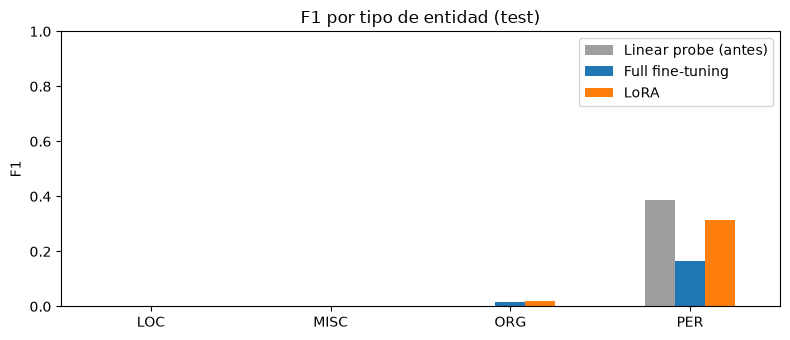

In [19]:
# F1 por entidad: full vs. LoRA vs. probe
f1_ent = pd.DataFrame({NOMBRES[m]: {e: v['f1'] for e, v in resultados[m]['per_entity'].items()} for m in resultados})
f1_ent.plot.bar(figsize=(8, 3.5), rot=0, color=colores, title='F1 por tipo de entidad (test)')
plt.ylim(0, 1); plt.ylabel('F1'); plt.tight_layout(); plt.show()

**Inferencia.** Cargamos los modelos desde disco: el full desde su carpeta y el LoRA como `PeftModel.from_pretrained(modelo_base, adaptador)` — el backbone se descarga del Hub y solo se lee el adaptador de pocos MB. Se predice una etiqueta por palabra (la del primer subtoken).

In [20]:
def load_trained(mode):
    ckpt = resultados[mode]['ckpt_dir']
    if mode == 'lora':
        return PeftModel.from_pretrained(load_base_model(), ckpt).to(device).eval()
    return AutoModelForTokenClassification.from_pretrained(ckpt).to(device).eval()

@torch.no_grad()
def predecir(model, palabras):
    enc = tokenizer(palabras, is_split_into_words=True, return_tensors='pt', truncation=True, max_length=MAX_LEN)
    pred = model(**{k: v.to(device) for k, v in enc.items()}).logits.argmax(-1)[0].tolist()
    out, prev = [], None
    for idx, wid in enumerate(enc.word_ids()):
        if wid is not None and wid != prev:
            out.append(id2label[pred[idx]])
        prev = wid
    return out

oracion = ('Lionel Messi left FC Barcelona in 2021 and signed for Paris Saint-Germain , '
           'a club owned by Qatar Sports Investments , before moving to Inter Miami in the United States .').split()
inferencia = pd.DataFrame({'palabra': oracion})
for mode in resultados:
    m = load_trained(mode)
    inferencia[NOMBRES[mode]] = predecir(m, oracion)
    del m
inferencia.set_index('palabra').T

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


palabra,Lionel,Messi,left,FC,Barcelona,in,2021,and,signed,for,...,before,moving,to,Inter,Miami,in,the,United,States,.
Linear probe (antes),O,I-LOC,I-PER,I-PER,I-PER,B-LOC,B-PER,B-LOC,B-PER,O,...,O,I-ORG,O,O,I-PER,B-PER,I-ORG,I-ORG,I-ORG,O
Full fine-tuning,O,O,I-PER,I-PER,I-PER,B-LOC,B-PER,B-LOC,B-PER,I-ORG,...,O,B-PER,I-ORG,O,O,B-PER,I-ORG,O,O,O
LoRA,O,I-LOC,I-PER,I-PER,I-PER,B-LOC,B-PER,O,B-PER,O,...,O,O,O,O,I-PER,O,O,O,O,O


## 9. Conclusiones

Las conclusiones se **calculan** a partir de las métricas obtenidas arriba (no están escritas a mano): ranking por F1, brecha full vs. LoRA, mejora sobre el probe, ratio de parámetros entrenables, ratio de tamaño del checkpoint, memoria y tiempo.

In [21]:
P, F, L = resultados['probe'], resultados['full'], resultados['lora']
f1 = {m: r['test']['f1'] for m, r in resultados.items()}
acc = {m: r['test']['accuracy'] for m, r in resultados.items()}

ranking = sorted(f1, key=f1.get, reverse=True)
print('Ranking por F1 de entidad en test: ' + ' > '.join(f'{NOMBRES[m]} ({f1[m]:.4f})' for m in ranking))

gap = F['test']['f1'] - L['test']['f1']
ganador = 'full' if gap > 0 else 'LoRA' if gap < 0 else 'ninguno (empate)'
rel = f' ({100 * L["test"]["f1"] / F["test"]["f1"]:.1f}% del F1 de full)' if F['test']['f1'] > 0 else ''
print(f'\n1) Calidad: full logra F1={F["test"]["f1"]:.4f} y LoRA F1={L["test"]["f1"]:.4f}; '
      f'brecha full−LoRA = {gap:+.4f} puntos de F1{rel}. Gana: {ganador}.')
base_O = np.mean([t == 'O' for seq in F['y_true'] for t in seq])
print(f'   Accuracy por palabra: full {acc["full"]:.4f} vs. LoRA {acc["lora"]:.4f}; como referencia, predecir '
      f'siempre O ya daría accuracy {base_O:.4f}, por eso el F1 de entidad es la métrica que discrimina.')

print(f'\n2) Antes vs. después: el linear probe (backbone congelado, 1 época) llega a F1={P["test"]["f1"]:.4f}. '
      f'El fine-tuning suma ΔF1 = {F["test"]["f1"] - P["test"]["f1"]:+.4f} (full) y '
      f'{L["test"]["f1"] - P["test"]["f1"]:+.4f} (LoRA);')
print(f'   Δacc = {acc["full"] - acc["probe"]:+.4f} (full) y {acc["lora"] - acc["probe"]:+.4f} (LoRA).')
if F['test']['f1'] - P['test']['f1'] > 0:
    frac = (L['test']['f1'] - P['test']['f1']) / (F['test']['f1'] - P['test']['f1'])
    print(f'   LoRA recupera el {100 * frac:.1f}% de la mejora que obtiene el full fine-tuning sobre el probe.')

ratio_p = F['n_trainable'] / L['n_trainable']
print(f'\n3) Parámetros entrenables: full {F["n_trainable"]:,} ({100 * F["n_trainable"] / F["n_total"]:.1f}%) vs. '
      f'LoRA {L["n_trainable"]:,} ({100 * L["n_trainable"] / L["n_total"]:.3f}%) -> '
      f'LoRA entrena {ratio_p:,.0f} veces menos parámetros.')

ratio_s = F['ckpt_mb'] / L['ckpt_mb']
print(f'\n4) Checkpoint: full = {F["ckpt_mb"] / 1e3:.3f} GB vs. adaptador LoRA = {L["ckpt_mb"]:.2f} MB '
      f'-> el adaptador es {ratio_s:,.0f} veces más chico (un backbone compartido, un adaptador por tarea).')

if F['peak_mem_gb'] is not None and L['peak_mem_gb'] is not None:
    ahorro = 100 * (1 - L['peak_mem_gb'] / F['peak_mem_gb'])
    print(f'\n5) Memoria pico de GPU: full {F["peak_mem_gb"]:.2f} GB vs. LoRA {L["peak_mem_gb"]:.2f} GB '
          f'({ahorro:+.1f}% de ahorro con LoRA). LoRA no guarda gradientes ni momentos de Adam de los pesos '
          f'congelados, pero sí las activaciones, que no cambian respecto de full.')
else:
    print('\n5) Memoria pico de GPU: N/A (se ejecutó sin CUDA).')

ratio_t = F['train_time_s'] / max(L['train_time_s'], 1e-9)
print(f'\n6) Tiempo de entrenamiento: full {F["train_time_s"] / 60:.2f} min vs. LoRA {L["train_time_s"] / 60:.2f} min '
      f'(ratio full/LoRA = {ratio_t:.2f}).')
if ratio_t < ratio_p:
    print('   El ahorro de tiempo es mucho menor que el de parámetros: LoRA igual hace forward y backward por todo '
          'el backbone; solo se ahorra calcular y aplicar los gradientes de los pesos congelados.')

ent_gap = {e: F['per_entity'][e]['f1'] - L['per_entity'][e]['f1'] for e in F['per_entity'] if e in L['per_entity']}
if ent_gap:
    peor = max(ent_gap, key=lambda e: abs(ent_gap[e]))
    print(f'\n7) Por entidad, la mayor brecha full−LoRA (en valor absoluto) está en {peor} ({ent_gap[peor]:+.4f} de F1); '
          + ', '.join(f'{e}: {g:+.4f}' for e, g in ent_gap.items()) + '.')

if SMOKE_TEST:
    print('\n[SMOKE_TEST] Subconjunto diminuto y 1 época en CPU: los números anteriores solo verifican que el código corre.')

Ranking por F1 de entidad en test: Linear probe (antes) (0.1502) > LoRA (0.1321) > Full fine-tuning (0.0640)

1) Calidad: full logra F1=0.0640 y LoRA F1=0.1321; brecha full−LoRA = -0.0681 puntos de F1 (206.4% del F1 de full). Gana: LoRA.
   Accuracy por palabra: full 0.3176 vs. LoRA 0.4742; como referencia, predecir siempre O ya daría accuracy 0.7575, por eso el F1 de entidad es la métrica que discrimina.

2) Antes vs. después: el linear probe (backbone congelado, 1 época) llega a F1=0.1502. El fine-tuning suma ΔF1 = -0.0862 (full) y -0.0181 (LoRA);
   Δacc = -0.0322 (full) y +0.1245 (LoRA).

3) Parámetros entrenables: full 65,197,833 (100.0%) vs. LoRA 154,377 (0.236%) -> LoRA entrena 422 veces menos parámetros.

4) Checkpoint: full = 0.261 GB vs. adaptador LoRA = 0.63 MB -> el adaptador es 417 veces más chico (un backbone compartido, un adaptador por tarea).

5) Memoria pico de GPU: N/A (se ejecutó sin CUDA).

6) Tiempo de entrenamiento: full 0.09 min vs. LoRA 0.07 min (ratio full/LoR

## 10. Referencias

- Sanh, V., Debut, L., Chaumond, J., & Wolf, T. (2019). *DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter*. arXiv:1910.01108.
- Hu, E. J., Shen, Y., Wallis, P., et al. (2021). *LoRA: Low-Rank Adaptation of Large Language Models*. arXiv:2106.09685.
- Tjong Kim Sang, E. F., & De Meulder, F. (2003). *Introduction to the CoNLL-2003 Shared Task: Language-Independent Named Entity Recognition*. CoNLL 2003.
- Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. NAACL.
- Material de la cátedra: Unidad IV — *Hugging Face y fine-tuning eficiente*; NB2 — *Fine-tuning completo vs. eficiente*.